In [2]:
import pandas as pd 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib

df = pd.read_csv("../datasets/reddit.csv")
df.rename(columns={'clean_text': 'message', 'is_depression': 'label'}, inplace=True)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(df["message"], df['label'], test_size=0.3)
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', MultinomialNB())
])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

classification_report_result = classification_report(y_test, y_pred)
print(classification_report_result)

              precision    recall  f1-score   support

           0       0.99      0.50      0.66      1181
           1       0.66      0.99      0.79      1139

    accuracy                           0.74      2320
   macro avg       0.82      0.75      0.73      2320
weighted avg       0.83      0.74      0.72      2320



In [4]:
from xgboost import XGBClassifier


xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', xgb_model)
])
xgb_pipeline.fit(X_train, y_train)
y_pred_xgb = xgb_pipeline.predict(X_test)

classification_report_result = classification_report(y_test, y_pred_xgb)
print(classification_report_result)

/home/hyo/Documents/projects/trackerv2/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [00:25:29] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0       0.94      0.99      0.96      1181
           1       0.98      0.94      0.96      1139

    accuracy                           0.96      2320
   macro avg       0.96      0.96      0.96      2320
weighted avg       0.96      0.96      0.96      2320



In [5]:
from lightgbm import LGBMClassifier
lgbm_model = LGBMClassifier(n_jobs=-1, reg_lambda=0.1, num_leaves=64, max_depth=-1, learning_rate=0.1, n_estimators=100)
lgbm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', lgbm_model)
])
lgbm_pipeline.fit(X_train, y_train)
y_pred_lgbm = lgbm_pipeline.predict(X_test)
classification_report_result = classification_report(y_test, y_pred_lgbm)
print(classification_report_result)

[LightGBM] [Info] Number of positive: 2692, number of negative: 2719
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.068738 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 56366
[LightGBM] [Info] Number of data points in the train set: 5411, number of used features: 1359
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.497505 -> initscore=-0.009980
[LightGBM] [Info] Start training from score -0.009980
              precision    recall  f1-score   support

           0       0.94      0.99      0.96      1181
           1       0.99      0.93      0.96      1139

    accuracy                           0.96      2320
   macro avg       0.96      0.96      0.96      2320
weighted avg       0.96      0.96      0.96      2320



/home/hyo/Documents/projects/trackerv2/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [6]:
df.shape

(7731, 2)

In [7]:
df.groupby(df["label"]).count()

,message
label,
0,3900
1,3831


In [8]:
df_only_depression = df[df["label"] == 1].copy()
df_only_depression = df_only_depression.rename(columns={'message': 'sentence', 'label': 'emotion'})
df_only_depression["emotion"] = "depression"
df_only_depression

,sentence,emotion
0,we understand that most people who reply immed...,depression
1,welcome to r depression s check in post a plac...,depression
2,anyone else instead of sleeping more when depr...,depression
3,i ve kind of stuffed around a lot in my life d...,depression
4,sleep is my greatest and most comforting escap...,depression
...,...,...
3826,thlolo march eh it s because i don t want stre...,depression
3827,i hate it when i m having depression day and t...,depression
3828,educational depression,depression
3829,dmt powder helping with depression amp anxiety...,depression


<Axes: title={'center': 'Top 10 Emotions in Combined Data'}, xlabel='emotion'>

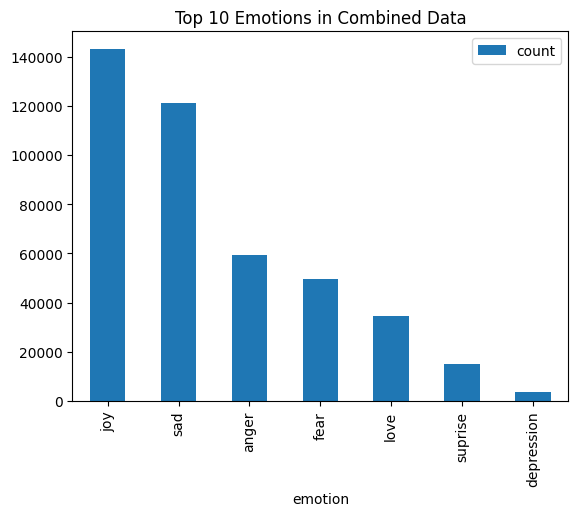

In [16]:
combined_emotion = pd.read_csv("combined_emotion.csv")
merged_df = pd.concat([combined_emotion, df_only_depression], ignore_index = True)
merged_df.groupby('emotion').size().reset_index(name='count').sort_values(by='count', ascending=False).head(10).plot(kind='bar', x='emotion', y='count', title='Top 10 Emotions in Combined Data')

In [10]:
X_train, X_test, y_train, y_test = train_test_split(merged_df["sentence"], merged_df['emotion'], test_size=0.3)

from lightgbm import LGBMClassifier
lgbm_model = LGBMClassifier(n_jobs=-1, reg_lambda=0.1, num_leaves=64, max_depth=-1, learning_rate=0.1, n_estimators=100)
lgbm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', lgbm_model)
])
lgbm_pipeline.fit(X_train, y_train)
y_pred_lgbm = lgbm_pipeline.predict(X_test)
classification_report_result = classification_report(y_test, y_pred_lgbm)
print(classification_report_result)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 3.408293 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 389245
[LightGBM] [Info] Number of data points in the train set: 298603, number of used features: 8686
[LightGBM] [Info] Start training from score -1.973759
[LightGBM] [Info] Start training from score -4.716662
[LightGBM] [Info] Start training from score -2.150590
[LightGBM] [Info] Start training from score -1.092316
[LightGBM] [Info] Start training from score -2.519479
[LightGBM] [Info] Start training from score -1.257417
[LightGBM] [Info] Start training from score -3.341663


/home/hyo/Documents/projects/trackerv2/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


              precision    recall  f1-score   support

       anger       0.89      0.93      0.91     17831
  depression       0.99      0.90      0.94      1160
        fear       0.84      0.87      0.85     14887
         joy       0.94      0.91      0.93     42904
        love       0.77      0.85      0.81     10516
         sad       0.96      0.93      0.95     36268
     suprise       0.69      0.71      0.70      4408

    accuracy                           0.90    127974
   macro avg       0.87      0.87      0.87    127974
weighted avg       0.90      0.90      0.90    127974



In [11]:
lgbm_pipeline.predict(["i missed my young brother so much", "i am so happy today because i got a new job"])

/home/hyo/Documents/projects/trackerv2/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


array(['sad', 'joy'], dtype=object)

In [20]:
merged_df.groupby('emotion').count()
merged_df.shape
X_train.shape

(298603,)

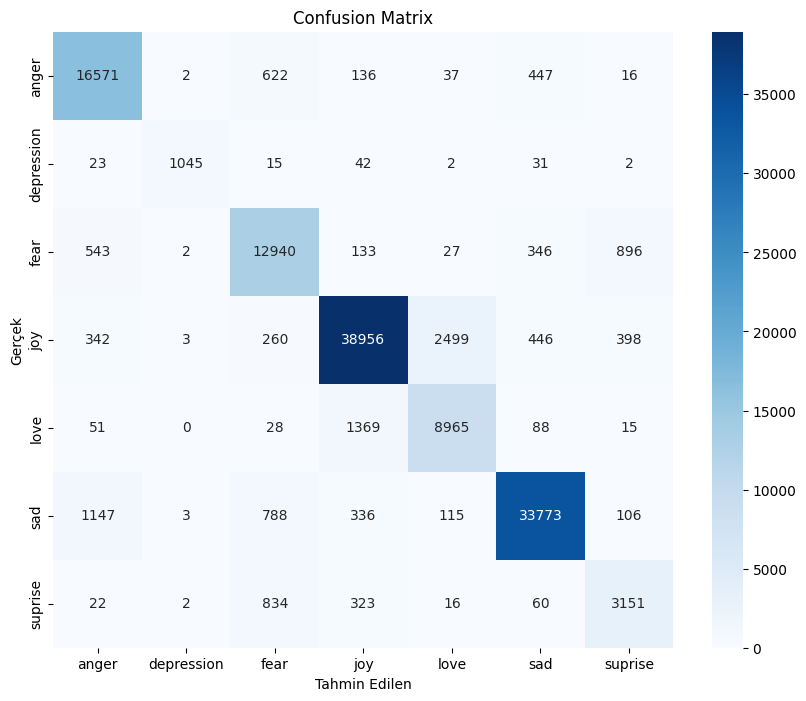

In [19]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

import matplotlib.pyplot as plt

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_lgbm, labels=sorted(y_test.unique()))

# Plot confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y_test.unique()),
            yticklabels=sorted(y_test.unique()))
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek')
plt.title('Confusion Matrix')
plt.savefig("confusion_matrix.png", bbox_inches='tight')
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(merged_df["sentence"], merged_df['emotion'], test_size=0.3)

from lightgbm import LGBMClassifier
lgbm_model = LGBMClassifier(n_jobs=-1, reg_lambda=0.1, num_leaves=64, max_depth=-1, learning_rate=0.1, n_estimators=100)
lgbm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000,  # Limit the number of features to 10,000
        ngram_range=(2, 3),  # Use unigrams and bigrams
        stop_words='english'  # Remove English stop words
    )),
    ('classifier', lgbm_model)
])
lgbm_pipeline.fit(X_train, y_train)
y_pred_lgbm = lgbm_pipeline.predict(X_test)
classification_report_result = classification_report(y_test, y_pred_lgbm)
print(classification_report_result)

In [23]:
from lightgbm import LGBMClassifier
import pandas as pd 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib

df = merged_df.copy()
df.rename(columns={'sentence': 'message', 'emotion': 'label'}, inplace=True)
X_train, X_test, y_train, y_test = train_test_split(df['message'], df['label'], test_size=0.3, random_state=42)
lgbm_model = LGBMClassifier(n_jobs=-1, reg_lambda=0.1, num_leaves=64, max_depth=-1, learning_rate=0.1, n_estimators=100)
lgbm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000, 
        ngram_range=( 1,3), 
        stop_words='english', 
        lowercase=True, 
        norm='l2', 
        use_idf=True, 
        smooth_idf=True, 
        sublinear_tf=True
    )),
    ('classifier', lgbm_model)
])
lgbm_pipeline.fit(X_train, y_train)
y_pred_lgbm = lgbm_pipeline.predict(X_test)
classification_report_result = classification_report(y_test, y_pred_lgbm)
print(classification_report_result)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 3.926775 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 439215
[LightGBM] [Info] Number of data points in the train set: 298603, number of used features: 9996
[LightGBM] [Info] Start training from score -1.974844
[LightGBM] [Info] Start training from score -4.698483
[LightGBM] [Info] Start training from score -2.149296
[LightGBM] [Info] Start training from score -1.093735
[LightGBM] [Info] Start training from score -2.508392
[LightGBM] [Info] Start training from score -1.257511
[LightGBM] [Info] Start training from score -3.357598


/home/hyo/Documents/projects/trackerv2/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


              precision    recall  f1-score   support

       anger       0.91      0.94      0.92     17876
  depression       0.97      0.91      0.94      1111
        fear       0.85      0.88      0.87     14842
         joy       0.94      0.92      0.93     43046
        love       0.78      0.86      0.82     10248
         sad       0.96      0.94      0.95     36276
     suprise       0.72      0.72      0.72      4575

    accuracy                           0.91    127974
   macro avg       0.88      0.88      0.88    127974
weighted avg       0.91      0.91      0.91    127974



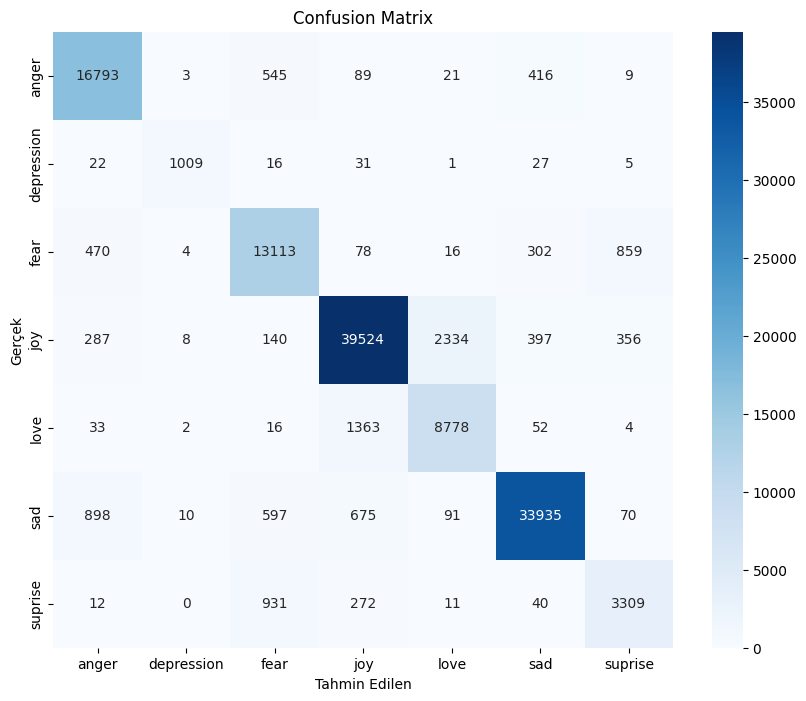

In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

import matplotlib.pyplot as plt

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_lgbm, labels=sorted(y_test.unique()))

# Plot confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y_test.unique()),
            yticklabels=sorted(y_test.unique()))
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek')
plt.title('Confusion Matrix')
plt.savefig("confusion_matrix.png", bbox_inches='tight')
plt.show()

In [29]:
lgbm_pipeline.predict(["i'm gonna kill you and make u suffered from my joy"])

/home/hyo/Documents/projects/trackerv2/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


array(['depression'], dtype=object)